# Machine Learning Research Assignment
## Predicting Bank Term Deposit Subscription Using Machine Learning





## 1. Install and import libraries

In [ ]:
!pip -q install -U scikit-learn scipy

import os, warnings, time, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             classification_report, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.inspection import permutation_importance
from scipy.stats import randint, loguniform

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
print("Libraries ready.")

Libraries ready.


## 2. Upload the Kaggle CSV file



Kaggle search page: https://www.kaggle.com/datasets?search=bank%20marketing%20bank-full

In [ ]:
uploaded = files.upload()  # Choose bank-full.csv from your computer

if not uploaded:
    raise ValueError("No file uploaded. Please upload bank-full.csv.")

filename = next(iter(uploaded))
df = pd.read_csv(filename, sep=None, engine="python")
df.columns = df.columns.str.strip()

print("Loaded file:", filename)
print("Dataset shape:", df.shape)
display(df.head())

Saving bank-full.csv to bank-full.csv
Loaded file: bank-full.csv
Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 3. Check dataset structure and assignment requirements

In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("data_type"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_values"))
print("\nDuplicate rows:", df.duplicated().sum())

assert len(df) >= 1000, "The dataset must contain at least 1,000 records."
assert "y" in df.columns, "Target column 'y' was not found. Check that you uploaded bank-full.csv."
assert df.shape[1] >= 9, "The dataset must contain at least 8 features plus target."

Rows: 45211
Columns: 17

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Data types:


,data_type
age,int64
job,object
marital,object
education,object
default,object
balance,int64
housing,object
loan,object
contact,object
day,int64



Missing values:


,missing_values
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0



Duplicate rows: 0


## 4. Define target and predictors

The target is `y`: `yes` means the client subscribed; `no` means the client did not subscribe.

We exclude `duration` from the main experiment because it is only known after the phone call. We also keep the target separate from all predictors.

In [ ]:
df = df.drop_duplicates().copy()

y = df["y"].astype(str).str.strip().str.lower().map({"no": 0, "yes": 1})
if y.isna().any():
    raise ValueError("Unexpected target labels found. Inspect df['y'].unique().")

excluded_columns = ["y"]
if "duration" in df.columns:
    excluded_columns.append("duration")

X = df.drop(columns=excluded_columns)
print("Excluded columns:", excluded_columns)
print("Predictor shape:", X.shape)
print("Target counts:")
display(y.value_counts().rename(index={0:"no", 1:"yes"}).to_frame("count"))
print("Target percentage:")
display((y.value_counts(normalize=True)*100).rename(index={0:"no", 1:"yes"}).round(2).to_frame("percent"))

Excluded columns: ['y', 'duration']
Predictor shape: (45211, 15)
Target counts:


,count
y,
no,39922
yes,5289


Target percentage:


,percent
y,
no,88.3
yes,11.7


## 5. Exploratory Data Analysis (EDA)



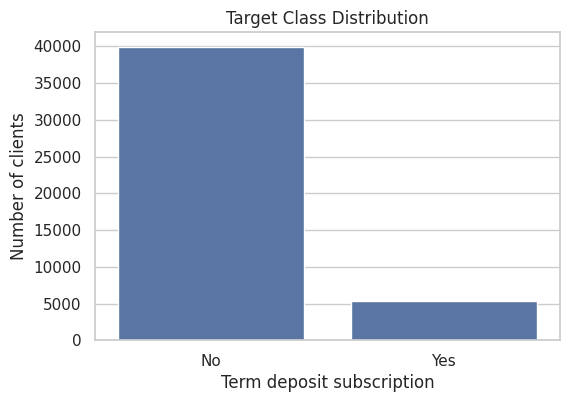

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x=y.map({0:"No", 1:"Yes"}))
plt.title("Target Class Distribution")
plt.xlabel("Term deposit subscription")
plt.ylabel("Number of clients")
plt.show()

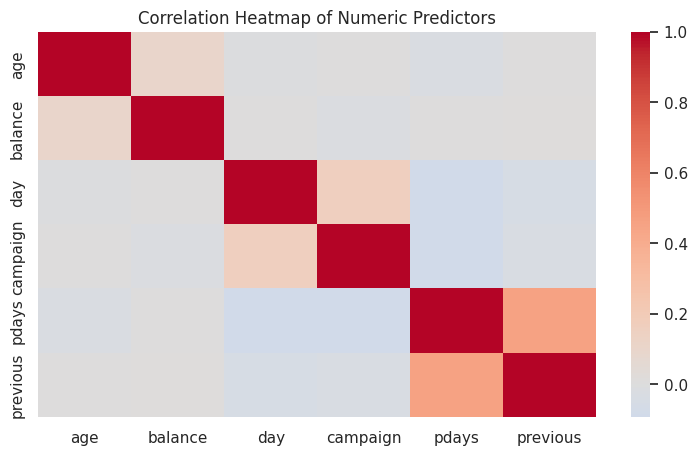

In [ ]:
plt.figure(figsize=(9,5))
numeric_all = X.select_dtypes(include=np.number)
sns.heatmap(numeric_all.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap of Numeric Predictors")
plt.show()

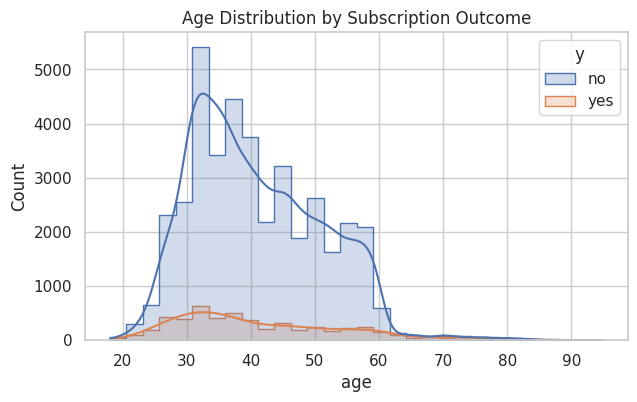

In [ ]:
if "age" in X.columns:
    plt.figure(figsize=(7,4))
    sns.histplot(data=df, x="age", hue="y", bins=30, kde=True, element="step")
    plt.title("Age Distribution by Subscription Outcome")
    plt.show()

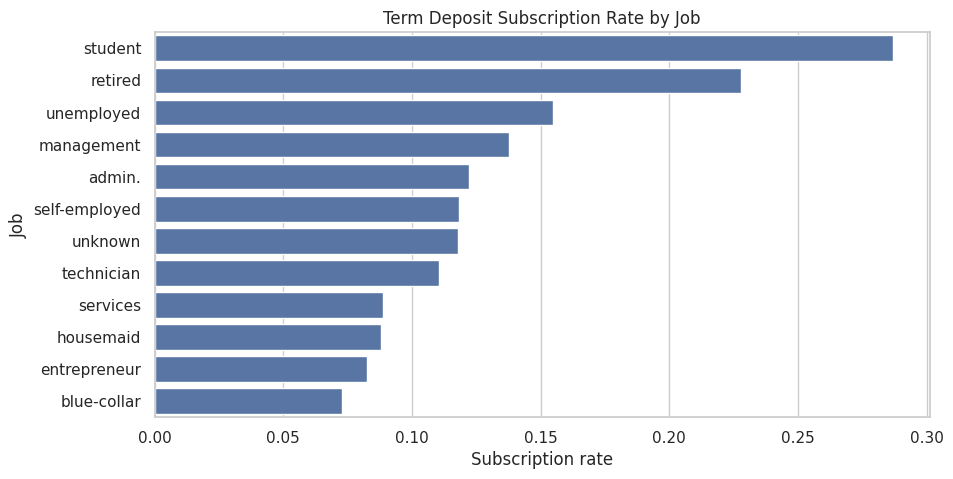

In [ ]:
if "job" in X.columns:
    job_rate = df.groupby("job")["y"].apply(lambda s: (s.astype(str).str.lower()=="yes").mean()).sort_values(ascending=False)
    plt.figure(figsize=(10,5))
    sns.barplot(x=job_rate.values, y=job_rate.index)
    plt.xlabel("Subscription rate")
    plt.ylabel("Job")
    plt.title("Term Deposit Subscription Rate by Job")
    plt.show()

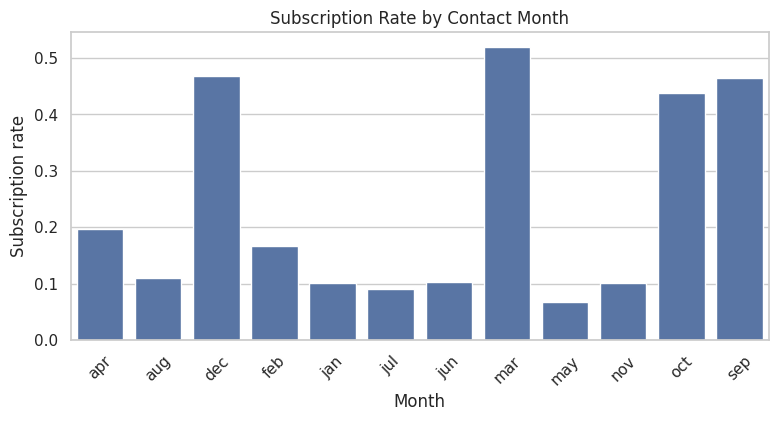

In [ ]:
if "month" in X.columns:
    month_rate = df.groupby("month")["y"].apply(lambda s: (s.astype(str).str.lower()=="yes").mean())
    plt.figure(figsize=(9,4))
    sns.barplot(x=month_rate.index, y=month_rate.values)
    plt.title("Subscription Rate by Contact Month")
    plt.xlabel("Month")
    plt.ylabel("Subscription rate")
    plt.xticks(rotation=45)
    plt.show()

## 6. Train-test split and leakage-safe preprocessing

We reserve 20% of the data as a final test set. The remaining 80% is used for training and cross-validation. Imputation, scaling, and one-hot encoding are placed inside a scikit-learn pipeline, so they are learned from training folds only.

We use stratification to preserve the target class ratio in both sets.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training records: 36168
Testing records: 9043
Numeric features: ['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


## 7. Baseline and machine-learning models

We compare a simple majority-class baseline with nine learning algorithms.

In [ ]:
models = {
    "Dummy baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced", random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7, weights="distance"),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE, max_iter=5000),
    "Decision Tree": DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE, max_depth=12),
    "Random Forest": RandomForestClassifier(n_estimators=250, class_weight="balanced_subsample", random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2),
    "Extra Trees": ExtraTreesClassifier(n_estimators=250, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, min_samples_leaf=2),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE, n_estimators=120, learning_rate=0.08, max_depth=2),
    "AdaBoost": AdaBoostClassifier(random_state=RANDOM_STATE, n_estimators=120, learning_rate=0.5),
    "MLP Neural Network": MLPClassifier(hidden_layer_sizes=(64,), max_iter=250, early_stopping=True, random_state=RANDOM_STATE)
}

results = []
fitted_models = {}
for name, estimator in models.items():
    print("Training:", name)
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    start = time.time()
    pipe.fit(X_train, y_train)
    elapsed = time.time() - start

    pred = pipe.predict(X_test)
    score = None
    if hasattr(pipe, "predict_proba"):
        score = pipe.predict_proba(X_test)[:, 1]
    elif hasattr(pipe, "decision_function"):
        score = pipe.decision_function(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, score) if score is not None else np.nan,
        "PR_AUC": average_precision_score(y_test, score) if score is not None else np.nan,
        "Training_Time_sec": elapsed
    })
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values("F1", ascending=False)
display(results_df.round(4))

Training: Dummy baseline
Training: Logistic Regression
Training: K-Nearest Neighbors
Training: Linear SVM
Training: Decision Tree
Training: Random Forest
Training: Extra Trees
Training: Gradient Boosting
Training: AdaBoost
Training: MLP Neural Network


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,Training_Time_sec
6,Extra Trees,0.8531,0.4003,0.5123,0.4494,0.7801,0.4181,13.3259
5,Random Forest,0.8870,0.5226,0.3941,0.4494,0.8026,0.4548,11.9370
4,Decision Tree,0.8316,0.3520,0.5227,0.4207,0.7196,0.3500,0.4196
3,Linear SVM,0.7578,0.2684,0.6200,0.3746,0.7718,0.4049,0.3699
1,Logistic Regression,0.7548,0.2662,0.6238,0.3732,0.7722,0.4093,0.6694
9,MLP Neural Network,0.8951,0.6236,0.2599,0.3669,0.7907,0.4430,5.4187
2,K-Nearest Neighbors,0.8891,0.5758,0.1975,0.2942,0.7138,0.3434,0.1833
7,Gradient Boosting,0.8942,0.6784,0.1815,0.2864,0.7940,0.4397,8.1611
8,AdaBoost,0.8935,0.7039,0.1550,0.2541,0.7666,0.3961,6.8518
0,Dummy baseline,0.8830,0.0000,0.0000,0.0000,0.5000,0.1170,0.1974


## 8. Visual comparison of model performance

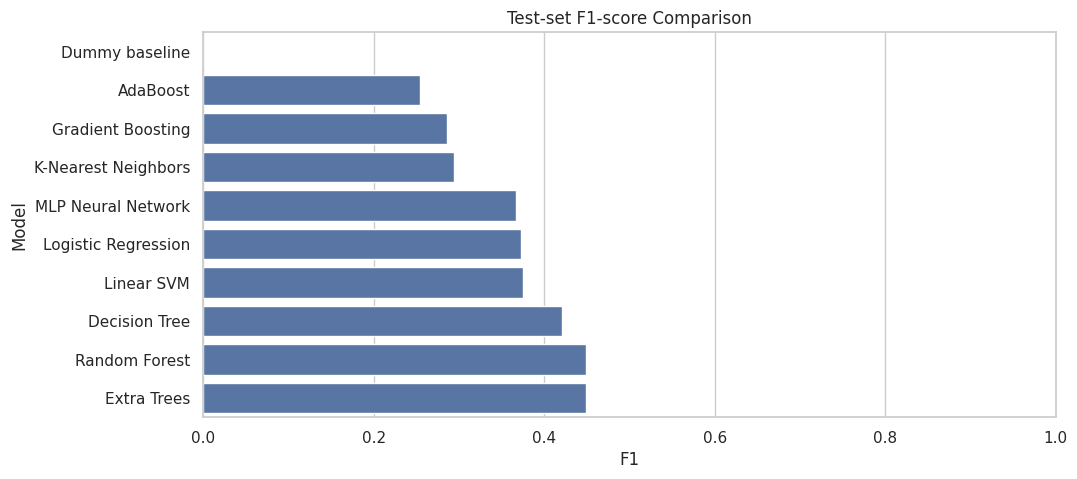

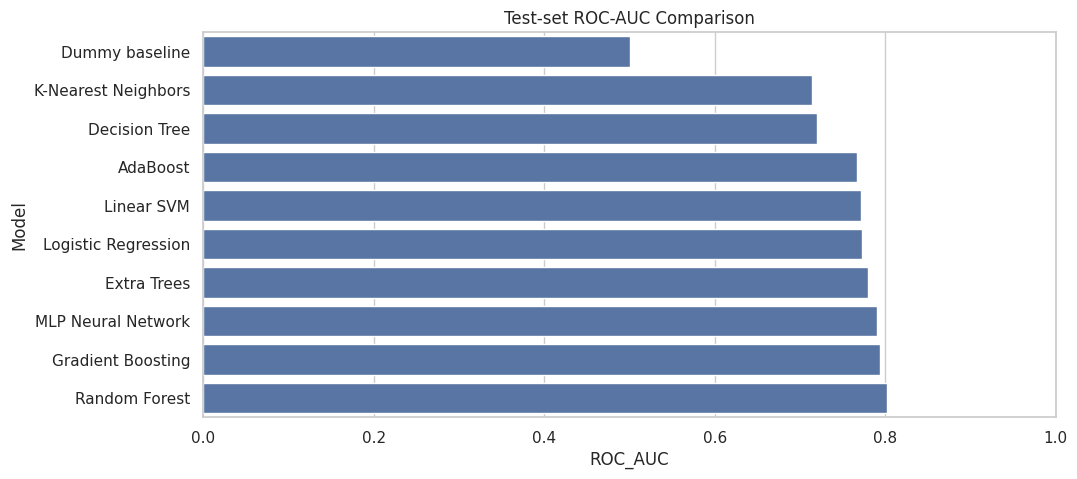

In [ ]:
plt.figure(figsize=(11,5))
plot_df = results_df.sort_values("F1", ascending=True)
sns.barplot(data=plot_df, x="F1", y="Model")
plt.title("Test-set F1-score Comparison")
plt.xlim(0, 1)
plt.show()

plt.figure(figsize=(11,5))
plot_df = results_df.sort_values("ROC_AUC", ascending=True)
sns.barplot(data=plot_df, x="ROC_AUC", y="Model")
plt.title("Test-set ROC-AUC Comparison")
plt.xlim(0, 1)
plt.show()

## 9. Hyperparameter tuning using training data only



In [ ]:
candidate_names = [n for n in results_df["Model"].tolist() if n != "Dummy baseline"][:3]
print("Models selected for tuning:", candidate_names)

param_spaces = {
    "Logistic Regression": {
        "model__C": loguniform(0.01, 10)
    },
    "K-Nearest Neighbors": {
        "model__n_neighbors": randint(5, 20),
        "model__weights": ["uniform", "distance"]
    },
    "Linear SVM": {
        "model__C": loguniform(0.01, 10)
    },
    "Decision Tree": {
        "model__max_depth": randint(4, 25),
        "model__min_samples_leaf": randint(1, 10)
    },
    "Random Forest": {
        "model__n_estimators": randint(150, 350),
        "model__max_depth": [None, 10, 16, 22],
        "model__min_samples_leaf": randint(1, 5)
    },
    "Extra Trees": {
        "model__n_estimators": randint(150, 350),
        "model__max_depth": [None, 10, 16, 22],
        "model__min_samples_leaf": randint(1, 5)
    },
    "Gradient Boosting": {
        "model__n_estimators": randint(80, 180),
        "model__learning_rate": loguniform(0.02, 0.2),
        "model__max_depth": randint(1, 4)
    },
    "AdaBoost": {
        "model__n_estimators": randint(80, 180),
        "model__learning_rate": loguniform(0.03, 1.0)
    },
    "MLP Neural Network": {
        "model__hidden_layer_sizes": [(32,), (64,), (64, 32)],
        "model__alpha": loguniform(1e-5, 1e-2)
    }
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
tuned_models = {}
tuning_rows = []

for name in candidate_names:
    print("\nTuning:", name)
    estimator = models[name]
    pipe = Pipeline([("preprocess", preprocessor), ("model", estimator)])
    search = RandomizedSearchCV(
        pipe, param_distributions=param_spaces[name],
        n_iter=5, scoring="f1", cv=cv, n_jobs=-1,
        random_state=RANDOM_STATE, verbose=1
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    tuning_rows.append({
        "Model": name,
        "Best_CV_F1": search.best_score_,
        "Best_parameters": str(search.best_params_)
    })

tuning_df = pd.DataFrame(tuning_rows).sort_values("Best_CV_F1", ascending=False)
display(tuning_df)

Models selected for tuning: ['Extra Trees', 'Random Forest', 'Decision Tree']

Tuning: Extra Trees
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Tuning: Random Forest
Fitting 3 folds for each of 5 candidates, totalling 15 fits

Tuning: Decision Tree
Fitting 3 folds for each of 5 candidates, totalling 15 fits


,Model,Best_CV_F1,Best_parameters
1,Random Forest,0.466510,"{'model__max_depth': 16, 'model__min_samples_l..."
0,Extra Trees,0.433606,"{'model__max_depth': 16, 'model__min_samples_l..."
2,Decision Tree,0.413475,"{'model__max_depth': 10, 'model__min_samples_l..."


## 10. Final evaluation of tuned models on the untouched test set

In [ ]:
final_rows = []
for name, pipe in tuned_models.items():
    pred = pipe.predict(X_test)
    if hasattr(pipe, "predict_proba"):
        score = pipe.predict_proba(X_test)[:, 1]
    else:
        score = pipe.decision_function(X_test)
    final_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, score),
        "PR_AUC": average_precision_score(y_test, score)
    })

final_df = pd.DataFrame(final_rows).sort_values("F1", ascending=False)
display(final_df.round(4))

best_name = final_df.iloc[0]["Model"]
best_model = tuned_models[best_name]
print("Best tuned model by test F1:", best_name)
print(classification_report(y_test, best_model.predict(X_test), target_names=["No", "Yes"]))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
1,Random Forest,0.8499,0.3981,0.5520,0.4626,0.8018,0.4530
0,Extra Trees,0.8190,0.3434,0.6002,0.4369,0.7906,0.4293
2,Decision Tree,0.8223,0.3407,0.5548,0.4222,0.7440,0.3770


Best tuned model by test F1: Random Forest
              precision    recall  f1-score   support

          No       0.94      0.89      0.91      7985
         Yes       0.40      0.55      0.46      1058

    accuracy                           0.85      9043
   macro avg       0.67      0.72      0.69      9043
weighted avg       0.87      0.85      0.86      9043



## 11. Confusion matrix and ROC / Precision-Recall curves

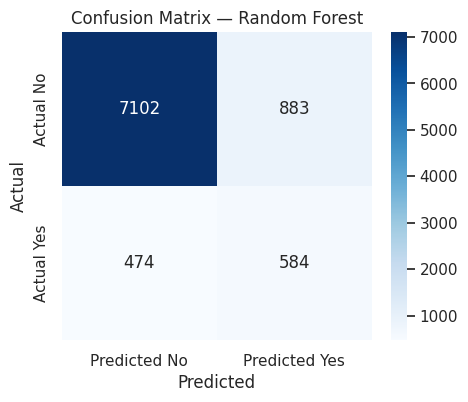

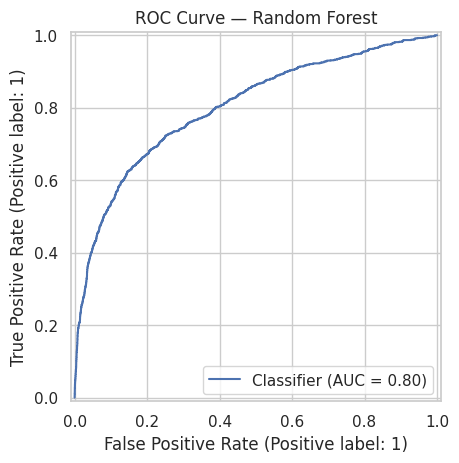

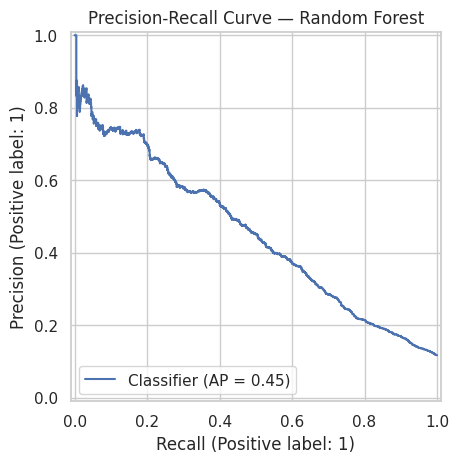

In [ ]:
best_pred = best_model.predict(X_test)
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title(f"Confusion Matrix — {best_name}")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.show()

if hasattr(best_model, "predict_proba"):
    best_score = best_model.predict_proba(X_test)[:, 1]
else:
    best_score = best_model.decision_function(X_test)

RocCurveDisplay.from_predictions(y_test, best_score)
plt.title(f"ROC Curve — {best_name}")
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, best_score)
plt.title(f"Precision-Recall Curve — {best_name}")
plt.show()

## 12. Statistical comparison: McNemar test

This compares the predictions of the two best tuned models on the same held-out test records. It tests whether their error patterns differ.

In [ ]:
from scipy.stats import binomtest

if len(final_df) >= 2:
    top_two = final_df["Model"].tolist()[:2]
    pred_a = tuned_models[top_two[0]].predict(X_test)
    pred_b = tuned_models[top_two[1]].predict(X_test)

    a_correct = (pred_a == y_test.to_numpy())
    b_correct = (pred_b == y_test.to_numpy())
    n01 = int(np.sum((~a_correct) & b_correct))
    n10 = int(np.sum(a_correct & (~b_correct)))
    discordant = n01 + n10

    if discordant > 0:
        p_value = binomtest(min(n01, n10), n=discordant, p=0.5, alternative="two-sided").pvalue
    else:
        p_value = 1.0

    print("Model A:", top_two[0])
    print("Model B:", top_two[1])
    print("A wrong, B correct:", n01)
    print("A correct, B wrong:", n10)
    print("Exact McNemar/binomial p-value:", p_value)
else:
    print("At least two tuned models are needed.")

Model A: Random Forest
Model B: Extra Trees
A wrong, B correct: 130
A correct, B wrong: 410
Exact McNemar/binomial p-value: 8.935140046341449e-35


## 13. Model interpretability: permutation importance



,Feature,Importance_Mean,Importance_Std
10,month,0.0999,0.0036
8,contact,0.0930,0.0015
6,housing,0.0379,0.0051
14,poutcome,0.0289,0.0030
9,day,0.0225,0.0067
12,pdays,0.0089,0.0008
11,campaign,0.0078,0.0008
5,balance,0.0059,0.0047
7,loan,0.0058,0.0054
1,job,0.0004,0.0006


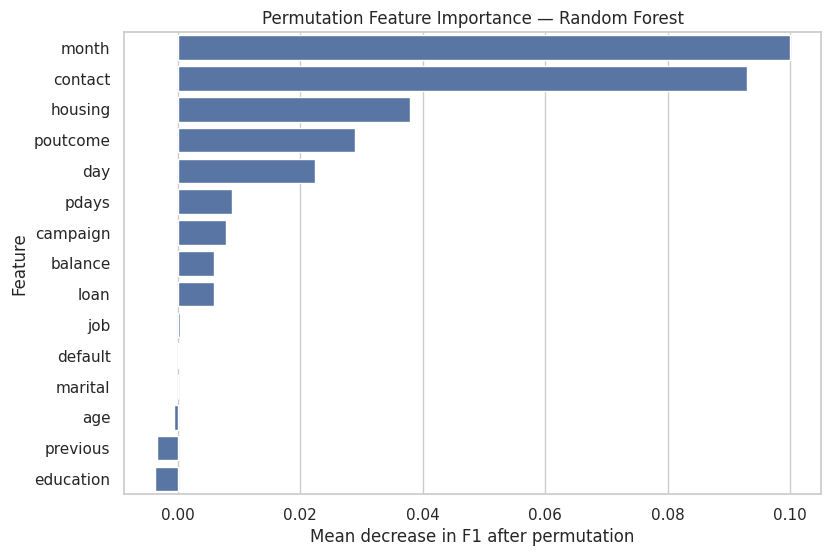

In [ ]:
perm = permutation_importance(
    best_model, X_test, y_test,
    scoring="f1", n_repeats=3,
    random_state=RANDOM_STATE, n_jobs=-1
)
importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance_Mean": perm.importances_mean,
    "Importance_Std": perm.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(importance_df.head(15).round(4))
plt.figure(figsize=(9,6))
sns.barplot(data=importance_df.head(15), x="Importance_Mean", y="Feature")
plt.title(f"Permutation Feature Importance — {best_name}")
plt.xlabel("Mean decrease in F1 after permutation")
plt.show()

## 14. Error analysis



In [ ]:
error_df = X_test.copy()
error_df["Actual"] = y_test.map({0:"No", 1:"Yes"})
error_df["Predicted"] = pd.Series(best_pred, index=X_test.index).map({0:"No", 1:"Yes"})
error_df["Error_Type"] = np.select(
    [(y_test.to_numpy()==1) & (best_pred==0),
     (y_test.to_numpy()==0) & (best_pred==1)],
    ["False Negative", "False Positive"],
    default="Correct"
)
display(error_df[error_df["Error_Type"] != "Correct"].head(20))
print("\nError counts:")
display(error_df["Error_Type"].value_counts().to_frame("count"))

,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome,Actual,Predicted,Error_Type
28083,35,admin.,divorced,secondary,no,1803,no,no,cellular,28,jan,2,-1,0,unknown,No,Yes,False Positive
33650,41,blue-collar,married,secondary,no,1384,yes,no,cellular,20,apr,4,340,4,success,No,Yes,False Positive
33749,42,self-employed,married,tertiary,no,10072,no,no,cellular,22,apr,1,-1,0,unknown,No,Yes,False Positive
43272,26,admin.,single,tertiary,no,3730,yes,no,cellular,11,mar,1,98,4,other,No,Yes,False Positive
29859,31,entrepreneur,single,tertiary,no,1957,no,no,cellular,4,feb,3,-1,0,unknown,No,Yes,False Positive
43303,42,management,married,tertiary,no,1205,no,no,telephone,15,mar,1,188,2,success,No,Yes,False Positive
44882,39,admin.,married,tertiary,no,1322,yes,no,cellular,24,sep,3,486,1,other,No,Yes,False Positive
34965,49,management,married,secondary,no,99,yes,no,cellular,6,may,2,343,1,failure,Yes,No,False Negative
39437,31,admin.,single,secondary,no,554,yes,no,cellular,25,may,3,103,2,failure,No,Yes,False Positive
39734,58,retired,married,secondary,no,3382,no,yes,cellular,28,may,2,309,2,failure,No,Yes,False Positive



Error counts:


,count
Error_Type,
Correct,7686
False Positive,883
False Negative,474


## 15. Save result tables for the paper

In [ ]:
results_df.to_csv("all_model_comparison.csv", index=False)
tuning_df.to_csv("hyperparameter_tuning_results.csv", index=False)
final_df.to_csv("tuned_model_test_results.csv", index=False)
importance_df.to_csv("permutation_feature_importance.csv", index=False)
print("Saved CSV result tables.")

Saved CSV result tables.
